In [25]:
import pandas as pd
import numpy as np
%pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt

In [26]:
df = pd.read_csv('student_exam_scores.csv', encoding='latin-1')
df

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3
...,...,...,...,...,...,...
195,S196,10.5,5.4,94.0,87,42.7
196,S197,7.1,6.1,85.1,92,40.4
197,S198,1.6,6.9,63.8,76,28.2
198,S199,12.0,7.3,50.5,58,42.0


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          200 non-null    object 
 1   hours_studied       200 non-null    float64
 2   sleep_hours         200 non-null    float64
 3   attendance_percent  200 non-null    float64
 4   previous_scores     200 non-null    int64  
 5   exam_score          200 non-null    float64
dtypes: float64(4), int64(1), object(1)
memory usage: 9.5+ KB


In [28]:
df.columns

Index(['student_id', 'hours_studied', 'sleep_hours', 'attendance_percent',
       'previous_scores', 'exam_score'],
      dtype='object')

In [29]:
df.describe()

,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,6.325500,6.622000,74.830000,66.800000,33.955000
std,3.227317,1.497138,14.249905,15.663869,6.789548
min,1.000000,4.000000,50.300000,40.000000,17.100000
25%,3.500000,5.300000,62.200000,54.000000,29.500000
50%,6.150000,6.700000,75.250000,67.500000,34.050000
75%,9.000000,8.025000,87.425000,80.000000,38.750000
max,12.000000,9.000000,100.000000,95.000000,51.300000


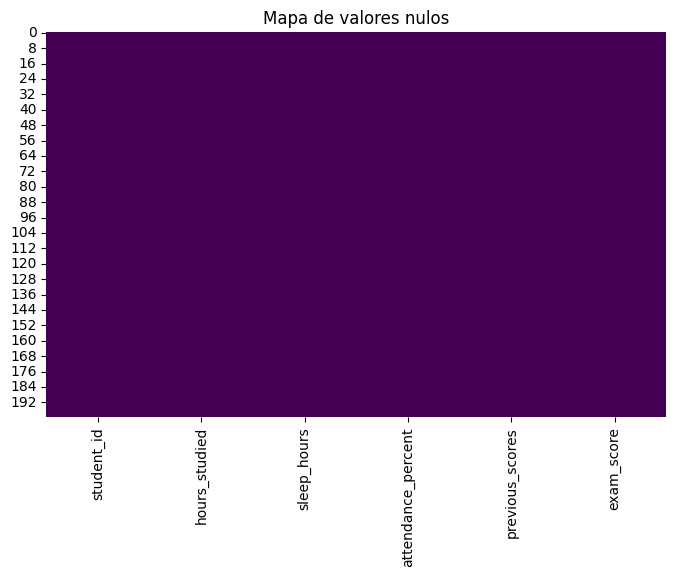

In [37]:
plt.figure(figsize=(8, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Mapa de valores nulos')
plt.show()

In [38]:
print("Valores nulos por columna:\n", df.isnull().sum())
print("Registros duplicados:", df.duplicated().sum())

Valores nulos por columna:
 student_id            0
hours_studied         0
sleep_hours           0
attendance_percent    0
previous_scores       0
exam_score            0
dtype: int64
Registros duplicados: 0


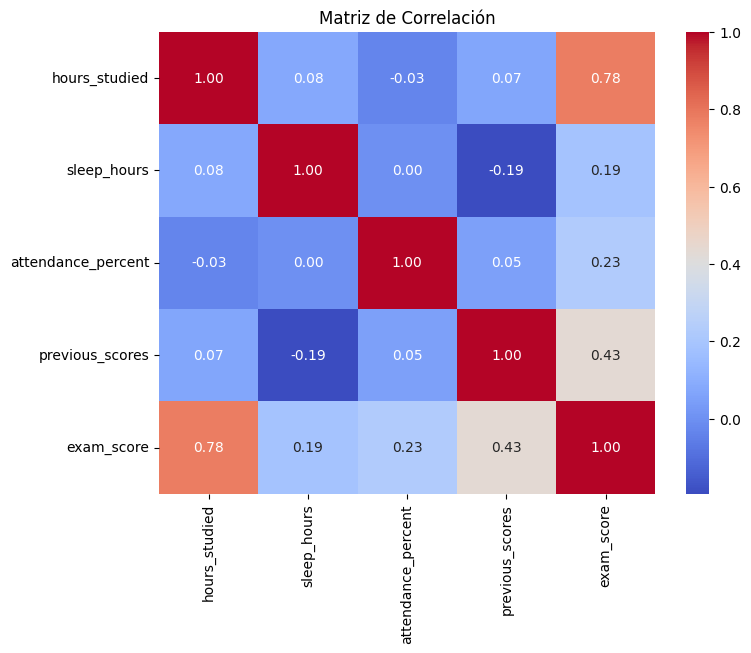

In [39]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.drop(columns=['student_id']).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación')
plt.show()

In [40]:
corr_target = df.drop(columns=['student_id']).corrwith(df['exam_score']).sort_values(ascending=False)
corr_target_df = pd.DataFrame(corr_target, columns=['Correlación'])
corr_target_df

,Correlación
exam_score,1.000000
hours_studied,0.776751
previous_scores,0.431105
attendance_percent,0.225713
sleep_hours,0.188222


In [41]:
X = df[['hours_studied', 'sleep_hours', 'attendance_percent', 'previous_scores']]
y = df['exam_score']

In [42]:
modelo = LinearRegression()
modelo.fit(X, y)

LinearRegression()

In [43]:
print(f"Intercepto (theta_0): {modelo.intercept_:.4f}")
for col, coef in zip(X.columns, modelo.coef_):
    print(f"Coeficiente para {col} (theta): {coef:.4f}")

Intercepto (theta_0): -2.1421
Coeficiente para hours_studied (theta): 1.5553
Coeficiente para sleep_hours (theta): 0.9523
Coeficiente para attendance_percent (theta): 0.1084
Coeficiente para previous_scores (theta): 0.1773


In [44]:
y_pred = modelo.predict(X)
print(f"R² Score: {r2_score(y, y_pred):.4f}")
print(f"Error Cuadrático Medio (MSE): {mean_squared_error(y, y_pred):.4f}")

R² Score: 0.8414
Error Cuadrático Medio (MSE): 7.2735


In [46]:
b0 = modelo.intercept_
b1 = modelo.coef_

calificacion = b0 + b1[0]*3 + b1[1]*5 + b1[2]*85 + b1[3]*78
print("La calificación estimada es de:\n", calificacion)

La calificación estimada es de:
 30.32633632911734


In [45]:
df.to_csv("student_exam_scores_clean.csv", index=False)

In [47]:
print("La calificación que se predice es de: \n", calificacion)

La calificación que se predice es de: 
 30.32633632911734


In [48]:
X.columns

Index(['hours_studied', 'sleep_hours', 'attendance_percent',
       'previous_scores'],
      dtype='object')